# 05 — Multifractal spatial structure of the SAAI field

Reproduces **§2.8** of *"Deepening before dissolution: non-monotonic escape dynamics
in the scaling exponents of county economies"*: the cross-sectional detrended
fluctuation analysis (DFA) of the annual SAAI field, its multifractal extension
(MFDFA) and the phase-randomised surrogate validation, the panel-wide distribution
of multifractal widths across years and specifications, and the fixed-sample-size
resampling test showing that the early-to-late decline of the width is not an
artefact of shrinking cross-sections. Together with the U-shaped diffusion of
notebook 03, these are the spatial fingerprints predicted by multiplicative noise:
$\alpha > 0.5$ (long-range correlations) and $\Delta h > 0$ (a non-degenerate
multifractal spectrum).

In [1]:
import os, sys
sys.path.insert(0, '/home/yushentang/EconP-release')
os.chdir('/home/yushentang/EconP-release')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from src.data_merger import load_panel
from src.saai import compute_saai
from src.dfa import (compute_cross_sectional_dfa,
                     compute_cross_sectional_dfa_timeseries,
                     compute_mfdfa, compute_mfdfa_surrogate_test)
from src.config import FP_PERIODS

COL = {"pre": "#4575b4", "during": "#e6a817", "post": "#d73027"}

def period_of(year):
    for p, (a, b) in FP_PERIODS.items():
        if a <= year <= b:
            return p
    return None

panel = load_panel("panel_scaling")
saai_multi = compute_saai(panel, y_col="GrossOutputValue",
                          x_cols=["PopNum", "CultivateArea"])
print(f"Multi-factor SAAI: {len(saai_multi):,} county-years, "
      f"{saai_multi['CountyCode'].nunique():,} counties, "
      f"years {int(saai_multi['Year'].min())}-{int(saai_multi['Year'].max())}")

/home/yushentang/.local/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


Loaded: /home/yushentang/EconP-release/data_clean/panel_scaling.parquet (19,392 rows, 64 cols)
Multi-factor SAAI: 10,278 county-years, 1,394 counties, years 2000-2023


## 1. Cross-sectional DFA

Each annual cross-section of the SAAI is treated as a one-dimensional *spatial*
series: counties are sorted by administrative code, which preserves approximate
geographic contiguity (province → prefecture → county). DFA integrates the
mean-removed series into a profile, partitions the profile into non-overlapping
windows of size $s$, removes a linear trend inside each window, and measures the
residual fluctuation $F(s)$. A power law $F(s)\sim s^{\alpha}$ defines the DFA
exponent: $\alpha = 0.5$ is spatial white noise, $\alpha = 1$ is $1/f$ (scale-free,
near-critical) organisation, and $\alpha > 0.5$ signals long-range correlation.

In [2]:
dfa = compute_cross_sectional_dfa_timeseries(saai_multi)   # sorts by CountyCode
dfa["period"] = dfa["Year"].map(period_of)

print("Cross-sectional DFA of the multi-factor SAAI (aggregates only):\n")
print(f"{'year':>6} {'n_counties':>11} {'alpha':>8} {'se':>7} {'R^2':>7}")
for _, r in dfa.iterrows():
    print(f"{int(r.Year):>6} {int(r.n_counties):>11} {r.alpha:>8.3f} "
          f"{r.alpha_se:>7.3f} {r.r_squared:>7.4f}")

mean_a, sd_a = dfa["alpha"].mean(), dfa["alpha"].std(ddof=1)
print(f"\nYears with a stable estimate: {len(dfa)} "
      f"({int(dfa.Year.min())}-{int(dfa.Year.max())})   (paper reports: 22 years, 2000-2021)")
print(f"Mean DFA exponent: alpha = {mean_a:.3f} +/- {sd_a:.3f}   "
      f"(paper reports: 0.91 +/- 0.07)")
print(f"Scaling quality: median R^2 = {dfa['r_squared'].median():.4f}, "
      f"min R^2 = {dfa['r_squared'].min():.4f}")

Cross-sectional DFA of the multi-factor SAAI (aggregates only):

  year  n_counties    alpha      se     R^2
  2000         793    0.814   0.019  0.9909
  2001         833    0.837   0.014  0.9954
  2002         867    0.887   0.011  0.9975
  2003         620    0.830   0.013  0.9958
  2004         785    0.903   0.012  0.9968
  2005         732    0.923   0.010  0.9979
  2006         553    0.943   0.014  0.9963
  2007         613    0.894   0.012  0.9968
  2008         562    0.903   0.013  0.9963
  2009         514    0.804   0.009  0.9979
  2010         295    0.869   0.016  0.9939
  2011         341    0.938   0.019  0.9933
  2012         347    0.929   0.017  0.9946
  2013         404    0.899   0.019  0.9927
  2014         387    0.939   0.011  0.9976
  2015         374    0.904   0.014  0.9959
  2016         385    0.951   0.016  0.9954
  2017         262    0.981   0.022  0.9917
  2018         247    0.931   0.017  0.9943
  2019         186    0.905   0.019  0.9932
  2020     

### Why 2022 and 2023 drop out

The estimator is not silently truncated: the last two cross-sections simply fail
the sample-size rules built into `src/dfa.py`. `compute_dfa` refuses a series with
fewer than 16 points (`status = "insufficient_data"`), and it builds its window
sizes log-spaced between 4 and $N/4$, so a very short series yields fewer than the
three distinct scales needed for a slope (`status = "insufficient_scales"`).
Multi-factor SAAI coverage collapses after 2019 because cultivated-area reporting
does — 23 counties in 2022 and 10 in 2023 — and neither year can support a
scaling fit.

In [3]:
print("Counties per annual multi-factor cross-section, 2019-2023:")
counts = saai_multi.groupby("Year")["SAAI"].count()
for y in range(2019, 2024):
    print(f"  {y}: {int(counts.get(y, 0)):>4} counties")

print("\nWhat the DFA estimator returns for the last two years:")
for y in (2022, 2023):
    res = compute_cross_sectional_dfa(saai_multi, y)
    print(f"  {y}: n = {res['n_counties']:>3}  ->  status = {res.get('status')}"
          + (f", valid scales = {res.get('n_valid')}" if "n_valid" in res else ""))
print("\nrules in src/dfa.py: N >= 16 points, and >= 3 usable window sizes "
      "drawn log-spaced from 4 to N//4")

Counties per annual multi-factor cross-section, 2019-2023:
  2019:  186 counties
  2020:   62 counties
  2021:   83 counties
  2022:   23 counties
  2023:   10 counties

What the DFA estimator returns for the last two years:
  2022: n =  23  ->  status = insufficient_scales, valid scales = 2
  2023: n =  10  ->  status = insufficient_data

rules in src/dfa.py: N >= 16 points, and >= 3 usable window sizes drawn log-spaced from 4 to N//4


### Temporal trend of $\alpha$

The exponent drifts upward across the sample. We report the ordinary least-squares
slope on all estimable years, and again after dropping 2020–2021, the two
small-sample endpoints (62 and 83 counties) whose leverage is largest.

In [4]:
tr = stats.linregress(dfa["Year"], dfa["alpha"])
sub = dfa[dfa["Year"] <= 2019]
tr_sub = stats.linregress(sub["Year"], sub["alpha"])

print(f"All {len(dfa)} years (2000-2021):        "
      f"slope = {tr.slope:+.4f}/yr, p = {tr.pvalue:.4f}")
print(f"Dropping 2020-2021 ({len(sub)} years):   "
      f"slope = {tr_sub.slope:+.4f}/yr, p = {tr_sub.pvalue:.4f}")
print("\npaper reports: +0.005 per year, p = 0.004, robust to excluding the "
      "small-sample endpoint years 2020-2021")
print("  -> both variants give p = 0.004 to three decimals; the quoted slope is "
      "the endpoint-robust one")

All 22 years (2000-2021):        slope = +0.0060/yr, p = 0.0039
Dropping 2020-2021 (20 years):   slope = +0.0049/yr, p = 0.0044

paper reports: +0.005 per year, p = 0.004, robust to excluding the small-sample endpoint years 2020-2021
  -> both variants give p = 0.004 to three decimals; the quoted slope is the endpoint-robust one


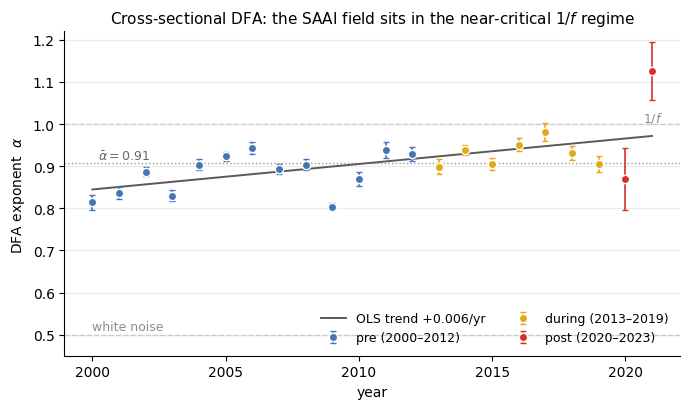

In [5]:
fig, ax = plt.subplots(figsize=(7.0, 4.2))
for p in ("pre", "during", "post"):
    d = dfa[dfa["period"] == p]
    if len(d) == 0:
        continue
    a, b = FP_PERIODS[p]
    ax.errorbar(d["Year"], d["alpha"], yerr=d["alpha_se"], fmt="o", ms=6,
                color=COL[p], ecolor=COL[p], elinewidth=1.2, capsize=2.5,
                mec="white", mew=1.0, zorder=4, label=f"{p} ({a}–{b})")

yy = np.array([dfa["Year"].min(), dfa["Year"].max()])
ax.plot(yy, tr.intercept + tr.slope * yy, color="0.35", lw=1.4, ls="-",
        zorder=3, label=f"OLS trend {tr.slope:+.3f}/yr")
ax.axhline(mean_a, color="0.6", lw=1, ls=":")
ax.text(2000.2, mean_a + 0.006, rf"$\bar\alpha = {mean_a:.2f}$",
        fontsize=9, color="0.4")
ax.axhline(1.0, color="0.8", lw=1, ls="--")
ax.text(2021.4, 1.006, r"$1/f$", fontsize=9, color="0.55", ha="right")
ax.axhline(0.5, color="0.8", lw=1, ls="--")
ax.text(2000.0, 0.512, "white noise", fontsize=9, color="0.55", ha="left")

ax.set_ylim(0.45, 1.22)
ax.set_xlabel("year")
ax.set_ylabel(r"DFA exponent  $\alpha$")
ax.set_title("Cross-sectional DFA: the SAAI field sits in the near-critical "
             r"$1/f$ regime", fontsize=11)
ax.legend(frameon=False, loc="lower right", fontsize=9, ncol=2)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="0.92", lw=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

## 2. MFDFA on a single cross-section

DFA characterises the field by one exponent; MFDFA generalises the fluctuation
function to arbitrary moment order $q$, so that $F_q(s)\sim s^{h(q)}$. Negative $q$
weights the quiet regions of the field, positive $q$ the bursty ones. A monofractal
field has $h(q)$ constant; a multifractal one has $h(q)$ decreasing, and the width

$$\Delta h = h(q_{\min}) - h(q_{\max}) = h(-5) - h(5) > 0$$

measures how strongly the local scaling varies across space. Non-constant diffusion
$B(\xi)$ in the Langevin description predicts exactly this: $\mathrm{d}h/\mathrm{d}q < 0$.
We run one live demonstration on the 2010 cross-section, the widest in the sample.

In [6]:
YEAR = 2010
cs = (saai_multi[saai_multi["Year"] == YEAR]
      .dropna(subset=["SAAI"]).sort_values("CountyCode"))
x2010 = cs["SAAI"].to_numpy()
print(f"{YEAR} cross-section: {len(x2010)} counties")

mf = compute_mfdfa(x2010)
delta_h = mf["h_q"][0] - mf["h_q"][-1]

print(f"\n{'q':>5} {'h(q)':>8} {'se':>7}")
for q, h, se in zip(mf["q"], mf["h_q"], mf["h_q_se"]):
    print(f"{q:>5.0f} {h:>8.3f} {se:>7.3f}")
print(f"\nMultifractal width Delta h = h(-5) - h(5) = {delta_h:.3f}   "
      f"(paper reports: 0.66)")
print(f"h(q) monotone decreasing: {bool(np.all(np.diff(mf['h_q']) < 0))}")

2010 cross-section: 295 counties

    q     h(q)      se
   -5    1.280   0.065
   -3    1.197   0.048
   -1    1.092   0.028
    0    1.039   0.020
    1    0.970   0.015
    2    0.869   0.016
    3    0.760   0.026
    5    0.621   0.037

Multifractal width Delta h = h(-5) - h(5) = 0.659   (paper reports: 0.66)
h(q) monotone decreasing: True


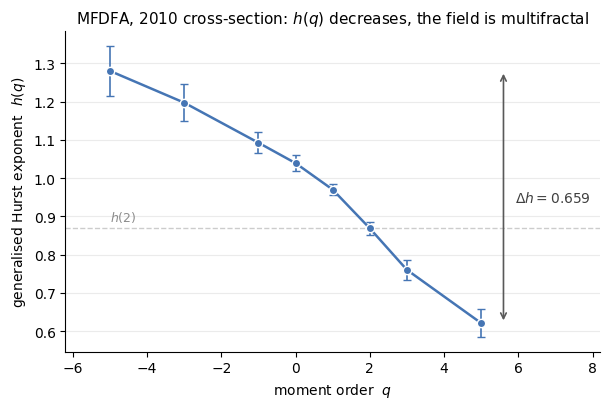

In [7]:
fig, ax = plt.subplots(figsize=(6.2, 4.2))
ax.errorbar(mf["q"], mf["h_q"], yerr=mf["h_q_se"], fmt="o-", ms=6, lw=1.8,
            color=COL["pre"], ecolor=COL["pre"], elinewidth=1.2, capsize=3,
            mec="white", mew=1.0)
h_lo, h_hi = mf["h_q"][0], mf["h_q"][-1]
ax.annotate("", xy=(5.6, h_hi), xytext=(5.6, h_lo),
            arrowprops=dict(arrowstyle="<->", color="0.35", lw=1.2))
ax.text(5.9, 0.5 * (h_lo + h_hi), rf"$\Delta h = {delta_h:.3f}$",
        va="center", fontsize=10, color="0.25")
ax.axhline(mf["h_q"][mf["q"] == 2][0], color="0.8", lw=1, ls="--")
ax.text(-5.0, mf["h_q"][mf["q"] == 2][0] + 0.02, "$h(2)$",
        fontsize=9, color="0.55")
ax.set_xlim(-6.2, 8.2)
ax.set_xlabel("moment order  $q$")
ax.set_ylabel("generalised Hurst exponent  $h(q)$")
ax.set_title(f"MFDFA, {YEAR} cross-section: $h(q)$ decreases, the field is "
             "multifractal", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="0.92", lw=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

## 3. Surrogate validation of the 2010 width

A positive $\Delta h$ can be produced by a linearly correlated field with a heavy
tail, so the width must be tested against a null that keeps the linear structure and
destroys everything else. The surrogates are phase-randomised: the Fourier amplitude
spectrum of the observed series is preserved exactly while the phases are drawn
uniformly, which retains the two-point autocorrelation and removes the nonlinear
(multiplicative) organisation.

The run below uses 199 surrogates so that it completes in seconds. The value quoted
in the paper uses 999 replicates per year and is produced by
`scripts/run_mfdfa_surrogates.py` ($z = 3.58$, $p = 0.004$).

In [8]:
st = compute_mfdfa_surrogate_test(x2010, n_surrogates=199, seed=42)
n_ge = int(np.sum(st["delta_h_surrogates"] >= st["delta_h_obs"]))

print(f"observed  Delta h = {st['delta_h_obs']:.3f}")
print(f"surrogate Delta h = {st['mean_surr']:.3f} +/- {st['std_surr']:.3f} "
      f"({st['n_valid_surrogates']} valid replicates)")
print(f"z = {st['z_score']:.2f}   "
      f"empirical p = {n_ge}/{st['n_valid_surrogates']} "
      f"(<= {1/(st['n_valid_surrogates']+1):.3f})")
print("\npaper reports: z = 3.58, p = 0.004 (999 surrogates, "
      "scripts/run_mfdfa_surrogates.py)")

observed  Delta h = 0.659
surrogate Delta h = 0.236 +/- 0.118 (199 valid replicates)
z = 3.58   empirical p = 0/199 (<= 0.005)

paper reports: z = 3.58, p = 0.004 (999 surrogates, scripts/run_mfdfa_surrogates.py)


## 4. The panel-wide picture (read from `results/tables/mfdfa_surrogate_yearly.csv`)

The claim of the section is not about 2010 but about the panel: every annual
cross-section, under both SAAI specifications, is tested against its own 999
surrogates. That is 44 surrogate ensembles and is **not rerun here** — the table is
read from `results/tables/mfdfa_surrogate_yearly.csv`, generated by
`scripts/run_mfdfa_surrogates.py`.

Individual years are noisy — an annual cross-section is a short series and the
surrogate null is broad — so the evidence is read at the panel level: the sign of
$\Delta h$ in every year, and Fisher's combination of the per-year p-values. The
combination assumes independence across years, which the overlapping county
composition violates; we therefore treat the combined p-values as indicative rather
than exact.

In [9]:
sur = pd.read_csv("results/tables/mfdfa_surrogate_yearly.csv")

print(f"{'spec':>7} {'years':>6} {'dh>0':>7} {'p<0.05':>8} {'median z':>9} "
      f"{'Fisher p':>11}")
fisher = {}
for spec in ("single", "multi"):
    d = sur[sur["spec"] == spec]
    pv = d["p"].clip(1e-4, 1).to_numpy()          # p = 0 floored at 1/(999+1)-ish
    chi2_stat = -2.0 * np.sum(np.log(pv))
    fisher[spec] = stats.chi2.sf(chi2_stat, 2 * len(pv))
    print(f"{spec:>7} {len(d):>6} {int((d['delta_h'] > 0).sum()):>4}/{len(d):<2} "
          f"{int((d['p'] < 0.05).sum()):>5}/{len(d):<2} {d['z'].median():>9.2f} "
          f"{fisher[spec]:>11.1e}")

print("\npaper reports: Delta h > 0 in all 24 single-factor years and all 20 "
      "estimable multi-factor years;")
print("               12 of 24 single-factor years and 6 of 20 multi-factor years "
      "significant at p < 0.05;")
print(f"               Fisher combined p ~ 3e-15 (single) -> {fisher['single']:.1e}, "
      f"3e-4 (multi) -> {fisher['multi']:.1e}")
print("               (about one significant year per specification would be "
      "expected by chance)")

   spec  years    dh>0   p<0.05  median z    Fisher p
 single     24   24/24    12/24      1.59     2.7e-15
  multi     20   20/20     6/20      0.16     2.7e-04

paper reports: Delta h > 0 in all 24 single-factor years and all 20 estimable multi-factor years;
               12 of 24 single-factor years and 6 of 20 multi-factor years significant at p < 0.05;
               Fisher combined p ~ 3e-15 (single) -> 2.7e-15, 3e-4 (multi) -> 2.7e-04
               (about one significant year per specification would be expected by chance)


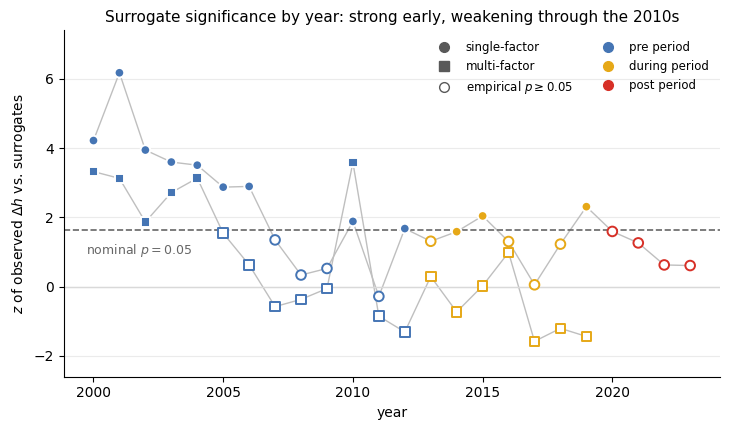

In [10]:
fig, ax = plt.subplots(figsize=(7.4, 4.4))
MARK = {"single": "o", "multi": "s"}
for spec in ("single", "multi"):
    d = sur[sur["spec"] == spec]
    sig = d["p"] < 0.05
    ax.plot(d["year"], d["z"], "-", lw=1.0, color="0.75", zorder=1)
    for flag in (True, False):
        dd = d[sig == flag]
        if len(dd) == 0:
            continue
        cols = [COL[period_of(int(y))] for y in dd["year"]]
        ax.scatter(dd["year"], dd["z"], marker=MARK[spec], s=48,
                   c=(cols if flag else ["white"] * len(dd)),
                   edgecolors=(["white"] * len(dd) if flag else cols),
                   linewidths=1.4, zorder=4)

ax.axhline(1.645, color="0.4", lw=1.2, ls="--")
ax.text(1999.7, 0.95, "nominal $p = 0.05$", fontsize=9, color="0.4", ha="left")
ax.axhline(0.0, color="0.85", lw=1.0)

handles = [plt.Line2D([], [], marker=MARK[s], ls="", ms=7, color="0.35",
                      label=f"{s}-factor") for s in ("single", "multi")]
handles += [plt.Line2D([], [], marker="o", ls="", ms=7, mfc="white",
                       mec="0.35", label="empirical $p \\geq 0.05$")]
handles += [plt.Line2D([], [], marker="o", ls="", ms=7, color=COL[p],
                       label=f"{p} period") for p in ("pre", "during", "post")]
ax.legend(handles=handles, frameon=False, fontsize=8.5, ncol=2,
          loc="upper right")
ax.set_xlabel("year")
ax.set_ylabel(r"$z$ of observed $\Delta h$ vs. surrogates")
ax.set_ylim(-2.6, 7.4)
ax.set_title("Surrogate significance by year: strong early, weakening through "
             "the 2010s", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="0.92", lw=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

## 5. Is the decline of $\Delta h$ a power artefact?

Individual-year significance is concentrated in 2000–2006 and fades afterwards, but
so does the number of counties per cross-section. Since a shorter series both widens
the surrogate null and destabilises $h(q)$ at extreme $q$, a spurious decline is a
real possibility.

The fixed-sample-size test removes the confound directly: every year is downsampled
$R = 200$ times to the *same* $n^{\star}$ (the smallest estimable cross-section in
that specification) and $\Delta h$ is re-estimated on each draw. This is a heavy
computation and is **not rerun here**; the medians are read from
`results/tables/mfdfa_fixedn_test.csv`, generated by `scripts/run_mfdfa_fixedn.py`,
which also verifies with `results/tables/mfdfa_fixedn_nulls.csv` that the surrogate
null width itself is stable at fixed $n$.

In [11]:
fx = pd.read_csv("results/tables/mfdfa_fixedn_test.csv")

paper_fx = {"multi": (0.0035, -0.75), "single": (0.0006, -0.56)}
for spec in ("multi", "single"):
    d = fx[fx["spec"] == spec]
    early = d[(d.year >= 2000) & (d.year <= 2006)]["dh_median"]
    late = d[(d.year >= 2013) & (d.year <= 2019)]["dh_median"]
    _, p_mw = stats.mannwhitneyu(early, late, alternative="greater")
    rho, p_rho = stats.spearmanr(d["year"], d["dh_median"])
    p_pap, rho_pap = paper_fx[spec]
    print(f"{spec:>7}: n* = {int(d['n_star'].iloc[0])} counties per draw, "
          f"{len(d)} years")
    print(f"          early (2000-06) median Delta h = {early.median():.3f}  vs  "
          f"late (2013-19) = {late.median():.3f}")
    print(f"          Mann-Whitney one-sided p = {p_mw:.4f} "
          f"(paper reports: {p_pap:.4f});  "
          f"Spearman rho = {rho:.2f} (paper reports: {rho_pap:.2f}), p = {p_rho:.1e}")

print("\nThe decline survives at a common sample size, so it is not a power "
      "artefact of shrinking cross-sections.")

  multi: n* = 186 counties per draw, 20 years
          early (2000-06) median Delta h = 0.595  vs  late (2013-19) = 0.408
          Mann-Whitney one-sided p = 0.0035 (paper reports: 0.0035);  Spearman rho = -0.75 (paper reports: -0.75), p = 1.6e-04
 single: n* = 638 counties per draw, 23 years
          early (2000-06) median Delta h = 0.540  vs  late (2013-19) = 0.326
          Mann-Whitney one-sided p = 0.0006 (paper reports: 0.0006);  Spearman rho = -0.56 (paper reports: -0.56), p = 5.3e-03

The decline survives at a common sample size, so it is not a power artefact of shrinking cross-sections.


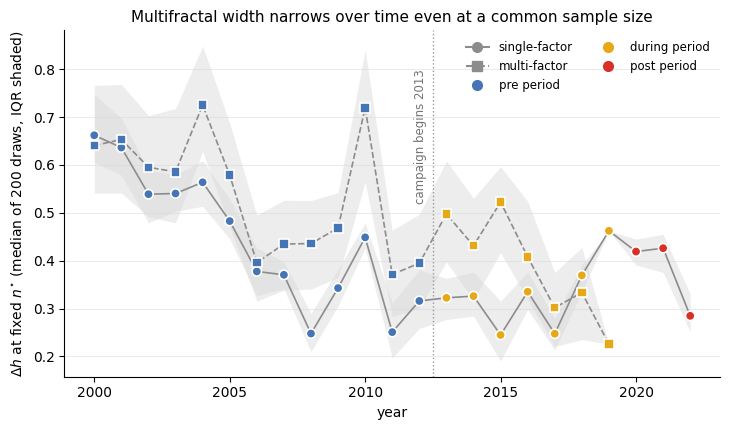

In [12]:
fig, ax = plt.subplots(figsize=(7.4, 4.4))
STYLE = {"single": dict(ls="-", marker="o"), "multi": dict(ls="--", marker="s")}
for spec in ("single", "multi"):
    d = fx[fx["spec"] == spec].sort_values("year")
    ax.fill_between(d["year"], d["dh_q25"], d["dh_q75"], color="0.85",
                    alpha=0.45, lw=0, zorder=1)
    ax.plot(d["year"], d["dh_median"], color="0.55", lw=1.2,
            ls=STYLE[spec]["ls"], zorder=2)
    cols = [COL[period_of(int(y))] for y in d["year"]]
    ax.scatter(d["year"], d["dh_median"], marker=STYLE[spec]["marker"], s=46,
               c=cols, edgecolors="white", linewidths=1.2, zorder=4)

ax.axvline(2012.5, color="0.6", lw=1, ls=":")
ax.text(2012.3, 0.80, "campaign begins 2013", rotation=90, va="top", ha="right",
        fontsize=8.5, color="0.45")
handles = [plt.Line2D([], [], marker=STYLE[s]["marker"], ls=STYLE[s]["ls"],
                      ms=7, color="0.55", label=f"{s}-factor")
           for s in ("single", "multi")]
handles += [plt.Line2D([], [], marker="o", ls="", ms=7, color=COL[p],
                       label=f"{p} period") for p in ("pre", "during", "post")]
ax.legend(handles=handles, frameon=False, fontsize=8.5, ncol=2, loc="upper right")
ax.set_xlabel("year")
ax.set_ylabel(r"$\Delta h$ at fixed $n^{\star}$ (median of 200 draws, IQR shaded)")
ax.set_title("Multifractal width narrows over time even at a common sample size",
             fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="0.92", lw=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

## Consistency with noise homogenisation

Two spatial statistics move in opposite directions over the sample: the DFA exponent
$\alpha$ rises (+0.005 per year), while the multifractal width $\Delta h$ falls. The
combination is what a compression of multiplicative noise looks like in space.
Multifractality is generated by *heterogeneity of the local noise amplitude*: when
different regions of the field are driven by very different effective $B$, local
scaling exponents differ and $h(q)$ has to bend. Flattening that amplitude landscape
removes the source of the bending — $\Delta h$ shrinks — while leaving a field whose
remaining fluctuations are more uniformly correlated across scales, which raises
$\alpha$. This is the spatial counterpart of the diffusion compression measured
dynamically in notebook 03 (the poverty-side $B$-ratio reversing from 1.55 to 0.56).

The alignment is a consistency check, not an attribution. The decline in $\Delta h$
is already under way well before 2013 — the fixed-$n$ medians fall through the
mid-2000s — so it cannot be assigned to the campaign; the section reports the two
mechanisms as mutually consistent descriptions of a homogenising noise field and
leaves the causal question to the attribution designs.

### Summary of reproduced quantities

| Quantity | Paper | This notebook |
|---|---|---|
| Estimable DFA years | 22 (2000–2021) | recomputed |
| Mean DFA exponent | $\bar\alpha = 0.91 \pm 0.07$ | recomputed |
| Trend in $\alpha$ | +0.005/yr, $p = 0.004$ | recomputed (full and endpoint-robust) |
| 2022 / 2023 exclusion | below minimum county count | reproduced from estimator status |
| $\Delta h$, 2010 cross-section | 0.66 | recomputed |
| Surrogate test, 2010 | $z = 3.58$, $p = 0.004$ (999 surrogates) | live 199-surrogate rerun |
| $\Delta h > 0$ in every year | 24/24 single, 20/20 multi | read from table |
| Years with $p < 0.05$ | 12/24 single, 6/20 multi | read from table |
| Fisher combined $p$ | $\sim 3\times10^{-15}$ / $3\times10^{-4}$ | read from table |
| Fixed-$n$ decline | MW $p = 0.0035$ / $0.0006$; $\rho = -0.75$ / $-0.56$ | read from table |